# ZeroTrace: delete a person from the AI, leave zero trace, prove it

IBM Z Datathon 2026 · Theme 2: Privacy, Identity & Secure AI · runs on IBM LinuxONE (s390x)

**Step 1 — Synthetic patient dataset.** 40,000 fictional patients with 10 health features and a high-risk label. No real personal data is used.

In [1]:
import numpy as np, pandas as pd
rng = np.random.default_rng(7)

N = 40000
age = rng.integers(18, 90, N)
bmi = rng.normal(27, 5, N).clip(15, 55).round(1)
systolic_bp = (rng.normal(120, 15, N) + (age - 50) * 0.4).clip(85, 210).round(0)
glucose = (rng.normal(100, 20, N) + (bmi - 27) * 1.5).clip(60, 300).round(0)
cholesterol = rng.normal(195, 35, N).clip(110, 350).round(0)
smoker = (rng.random(N) < 0.2).astype(int)
activity_hrs = rng.gamma(2, 1.5, N).round(1)
family_history = (rng.random(N) < 0.3).astype(int)
sleep_hrs = rng.normal(7, 1.1, N).clip(3, 11).round(1)
sex = rng.integers(0, 2, N)

logit = (-9.0 + 0.04*age + 0.08*bmi + 0.03*glucose + 0.01*systolic_bp
         + 0.6*smoker + 0.8*family_history - 0.15*activity_hrs)
high_risk = (rng.random(N) < 1 / (1 + np.exp(-logit))).astype(int)

patients = pd.DataFrame({
    'patient_id': [f'P{i:05d}' for i in range(N)],
    'age': age, 'sex': sex, 'bmi': bmi, 'systolic_bp': systolic_bp,
    'glucose': glucose, 'cholesterol': cholesterol, 'smoker': smoker,
    'activity_hrs': activity_hrs, 'family_history': family_history,
    'sleep_hrs': sleep_hrs, 'high_risk': high_risk,
})
patients.to_csv('patients.csv', index=False)
print("Patients:", patients.shape, "| High-risk rate:", round(high_risk.mean()*100, 1), "%")
patients.head()

Patients: (40000, 12) | High-risk rate: 39.7 %


,patient_id,age,sex,bmi,systolic_bp,glucose,cholesterol,smoker,activity_hrs,family_history,sleep_hrs,high_risk
0,P00000,86,1,21.7,142.0,85.0,182.0,0,2.5,1,6.2,0
1,P00001,63,0,29.4,94.0,100.0,162.0,0,1.1,0,7.4,0
2,P00002,67,0,26.0,122.0,105.0,183.0,1,4.5,0,5.0,1
3,P00003,82,1,24.3,155.0,82.0,171.0,0,0.9,1,6.2,1
4,P00004,59,1,30.3,150.0,123.0,203.0,0,0.8,0,7.2,1


**Step 2 — Sliced (SISA-style) model.** 30,000 patients are split into 10 slices; each slice trains its own random forest and the 10 vote. 5,000 never-seen patients are kept for calibration and 5,000 for testing. We compare against one big model trained on everyone.

In [2]:
import time, gc
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

FEATURES = ['age','sex','bmi','systolic_bp','glucose','cholesterol',
            'smoker','activity_hrs','family_history','sleep_hrs']
K = 10  

members = patients.iloc[:30000].copy()            
members['shard'] = np.arange(len(members)) % K
calib = patients.iloc[30000:35000].copy()         
test = patients.iloc[35000:].copy()               

def new_model():
    return RandomForestClassifier(n_estimators=50, bootstrap=False,
                                  max_features='sqrt', n_jobs=-1, random_state=0)

def train_shard(k):
    d = members[members.shard == k]
    m = new_model(); m.fit(d[FEATURES], d['high_risk']); return m

def sliced_predict(X):
    return np.mean([s.predict_proba(X)[:, 1] for s in shards], axis=0)

# Normal AI: one big model on everyone
t0 = time.time()
mono = new_model(); mono.fit(members[FEATURES], members['high_risk'])
mono_time = time.time() - t0
mono_acc = accuracy_score(test['high_risk'], mono.predict(test[FEATURES]))
del mono; gc.collect()

t0 = time.time()
shards = [train_shard(k) for k in range(K)]
sliced_time = time.time() - t0
t0 = time.time(); _ = train_shard(0); one_shard_time = time.time() - t0
sliced_acc = accuracy_score(test['high_risk'], (sliced_predict(test[FEATURES]) >= 0.5).astype(int))

print(f"Normal AI     - accuracy: {mono_acc:.3f} | retrain to forget someone: {mono_time:.2f}s")
print(f"ZeroTrace - accuracy: {sliced_acc:.3f} | retrain to forget someone: {one_shard_time:.2f}s")
print(f"Speed-up: {mono_time / one_shard_time:.1f}x faster")

Normal AI     - accuracy: 0.719 | retrain to forget someone: 1.08s
ZeroTrace - accuracy: 0.728 | retrain to forget someone: 0.14s
Speed-up: 7.4x faster


**Step 3a — First audit attempt (kept for transparency).** A per-slice percentile test. It fails (0% detected) because the forests were 100% confident on some outsiders too, so confidence alone did not separate insiders from outsiders.

In [3]:
def true_conf(model, df):
    p = model.predict_proba(df[FEATURES])
    return p[np.arange(len(df)), df['high_risk'].values]

# How confident each slice is on patients it has NEVER seen
calib_sorted = [np.sort(true_conf(shards[k], calib)) for k in range(K)]

def membership_scores(df):
    """For each patient: the highest 'I remember this person' percentile across slices."""
    pcts = []
    for k in range(K):
        c = true_conf(shards[k], df)
        pcts.append(np.searchsorted(calib_sorted[k], c, side='left') / len(calib_sorted[k]))
    pcts = np.array(pcts)
    return pcts.max(axis=0), pcts.argmax(axis=0)

THRESHOLD = 0.999
sample_members = members.sample(2000, random_state=1)
m_score, _ = membership_scores(sample_members)
t_score, _ = membership_scores(test.sample(2000, random_state=1))

print(f"Patients inside the AI correctly detected: {(m_score >= THRESHOLD).mean()*100:.1f}%")
print(f"Outsiders wrongly flagged:                {(t_score >= THRESHOLD).mean()*100:.1f}%")


Patients inside the AI correctly detected: 0.0%
Outsiders wrongly flagged:                0.0%


**Step 3b — Witness-slice audit (the working method).** Trees are made more varied (`max_features=2`, 100 trees). For each patient, the most confident slice is compared with the other 9 slices, which never saw that patient. The threshold is calibrated to a 1% false-alarm rate on never-seen patients.

In [4]:
def new_model():
    return RandomForestClassifier(n_estimators=100, bootstrap=False,
                                  max_features=2, n_jobs=-1, random_state=0)

t0 = time.time()
shards = [train_shard(k) for k in range(K)]
print(f"Retrained 10 slices in {time.time() - t0:.2f}s")
sliced_acc = accuracy_score(test['high_risk'], (sliced_predict(test[FEATURES]) >= 0.5).astype(int))
print(f"ZeroTrace accuracy: {sliced_acc:.3f}")

def gap_scores(df):
    C = np.array([true_conf(s, df) for s in shards])       
    C = np.clip(C, 0.001, 0.999)
    L = np.log(C / (1 - C))                                    
    top = L.max(axis=0)
    best = L.argmax(axis=0)
    others = (L.sum(axis=0) - top) / (K - 1)
    return top - others, best


calib_gap, _ = gap_scores(calib)
THRESHOLD = np.quantile(calib_gap, 0.99)

m_gap, m_best = gap_scores(sample_members)
t_gap, _ = gap_scores(test.sample(2000, random_state=1))
detected = m_gap >= THRESHOLD

print(f"\nPatients inside the AI correctly detected: {detected.mean()*100:.1f}%")
print(f"Outsiders wrongly flagged:                {(t_gap >= THRESHOLD).mean()*100:.1f}%")
print(f"Correct slice identified (when detected):  {(m_best[detected] == sample_members.shard.values[detected]).mean()*100:.1f}%")
print(f"\n(diagnostic) Outsiders getting 100% confidence on slice 0: "
      f"{(true_conf(shards[0], calib) == 1).mean()*100:.1f}%")

Retrained 10 slices in 2.25s
ZeroTrace accuracy: 0.728

Patients inside the AI correctly detected: 100.0%
Outsiders wrongly flagged:                0.9%
Correct slice identified (when detected):  99.3%

(diagnostic) Outsiders getting 100% confidence on slice 0: 0.1%


**Step 4 — Audit engine and SHA-256 model fingerprints.**

In [12]:
import hashlib, json, pickle
from datetime import datetime, timezone

def shard_hash(m):
    return hashlib.sha256(pickle.dumps(m)).hexdigest()
shard_hashes = [shard_hash(s) for s in shards]

def model_hash():
    return hashlib.sha256(''.join(shard_hashes).encode()).hexdigest()

calib_gap_sorted = np.sort(calib_gap)

def current_accuracy():
    p = sliced_predict(test[FEATURES])
    return accuracy_score(test['high_risk'], (p >= 0.5).astype(int))

def audit(pid):
    rec = patients[patients.patient_id == pid]
    gap, best = gap_scores(rec)
    gap, best = float(gap[0]), int(best[0])
    pct = float(np.searchsorted(calib_gap_sorted, gap, side='left') / len(calib_gap_sorted))
    return {'patient_id': pid, 'detected': bool(gap >= THRESHOLD),
            'memory_score': round(gap, 2),
            'stands_out_vs_outsiders_pct': round(pct * 100, 2),
            'suspected_slice': best}

ledger = []
print("Part A ready")

Part A ready


**Step 5 — Forget: delete the record, retrain only its slice, issue a hash-chained deletion certificate.**

In [13]:
def forget(pid):
    global members
    k = int(members[members.patient_id == pid].shard.iloc[0])
    before, acc_before, hash_before = audit(pid), current_accuracy(), model_hash()
    n_before = int((members.shard == k).sum())

    members = members[members.patient_id != pid]
    t0 = time.time()
    shards[k] = train_shard(k)
    secs = time.time() - t0
    shard_hashes[k] = shard_hash(shards[k])

    cert = {'certificate_id': f'FMN-{len(ledger) + 1:05d}', 'patient_id': pid,
            'issued_at_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
            'slice_retrained': k, 'slice_records_before': n_before,
            'slice_records_after': n_before - 1, 'retrain_seconds': round(secs, 3),
            'audit_before': before, 'audit_after': audit(pid),
            'accuracy_before': round(acc_before, 4),
            'accuracy_after': round(current_accuracy(), 4),
            'model_hash_before': hash_before, 'model_hash_after': model_hash(),
            'previous_certificate_hash': ledger[-1]['certificate_hash'] if ledger else '0' * 64}
    cert['certificate_hash'] = hashlib.sha256(json.dumps(cert, sort_keys=True).encode()).hexdigest()
    ledger.append(cert)
    json.dump(ledger, open('ledger.json', 'w'), indent=2)
    return cert

print("Part B ready")

Part B ready


**Step 6 — Ledger verification.** Recomputes every certificate hash and checks each link to the previous certificate.

In [14]:
def verify_ledger(chain):
    prev = '0' * 64
    for c in chain:
        body = {k: v for k, v in c.items() if k != 'certificate_hash'}
        ok_link = c['previous_certificate_hash'] == prev
        ok_hash = hashlib.sha256(json.dumps(body, sort_keys=True).encode()).hexdigest() == c['certificate_hash']
        if not (ok_link and ok_hash):
            return False, c['certificate_id']
        prev = c['certificate_hash']
    return True, None

print("Engine ready. Model fingerprint:", model_hash()[:16], "...")

Engine ready. Model fingerprint: 25660fe1d671a99c ...


**Step 7 — Three-act demo: audit → forget → prove.**

In [15]:
pid = 'P04821'

print("=== ACT 1: AUDIT ===")
a = audit(pid)
print(f"{pid} detected: {a['detected']} | stands out vs "
      f"{a['stands_out_vs_outsiders_pct']}% of outsiders | slice {a['suspected_slice']}")

print("\n=== ACT 2: FORGET ME ===")
cert = forget(pid)
print(f"Retrained slice {cert['slice_retrained']} in {cert['retrain_seconds']}s "
      f"(normal AI: {mono_time:.2f}s)")
print(f"Accuracy: {cert['accuracy_before']} -> {cert['accuracy_after']}")

print("\n=== ACT 3: PROVE IT ===")
print(f"Detected after forgetting: {cert['audit_after']['detected']}")
print(f"Certificate {cert['certificate_id']} | hash {cert['certificate_hash'][:20]}...")
print(f"Fingerprint: {cert['model_hash_before'][:12]}... -> {cert['model_hash_after'][:12]}...")

=== ACT 1: AUDIT ===
P04821 detected: True | stands out vs 99.7% of outsiders | slice 1

=== ACT 2: FORGET ME ===
Retrained slice 1 in 0.2s (normal AI: 1.08s)
Accuracy: 0.7284 -> 0.7298

=== ACT 3: PROVE IT ===
Detected after forgetting: False
Certificate FMN-00001 | hash 23c595244ce36c61e25a...
Fingerprint: 25660fe1d671... -> 77e88653ffa5...


**Step 8 — Tamper test and forgetting 20 random patients.**

In [16]:
print("=== TAMPER TEST ===")
print("Real ledger valid:", verify_ledger(ledger)[0])
fake = json.loads(json.dumps(ledger))
fake[0]['patient_id'] = 'P99999'
print("Edited ledger valid:", verify_ledger(fake)[0])

print("\n=== BIG TEST: forget 20 more patients ===")
batch = members.sample(20, random_state=5).patient_id.tolist()
before_det = [audit(p)['detected'] for p in batch]
certs = [forget(p) for p in batch]
after_det = [c['audit_after']['detected'] for c in certs]
print(f"Detected before: {sum(before_det)}/20 | after: {sum(after_det)}/20")
print(f"Avg forget time: {np.mean([c['retrain_seconds'] for c in certs]):.2f}s")
print(f"Final accuracy: {current_accuracy():.3f} | Certificates: {len(ledger)}")

=== TAMPER TEST ===
Real ledger valid: True
Edited ledger valid: False

=== BIG TEST: forget 20 more patients ===
Detected before: 20/20 | after: 0/20
Avg forget time: 0.19s
Final accuracy: 0.731 | Certificates: 21


**Save state** (models are not committed to the repo because of file size).

In [18]:
import joblib; joblib.dump({'shards': shards, 'shard_hashes': shard_hashes, 'members': members, 'THRESHOLD': THRESHOLD, 'calib_gap': calib_gap, 'mono_time': mono_time, 'FEATURES': FEATURES, 'K': K}, 'fmn_state.pkl'); print("Saved!")

Saved!


In [19]:
import importlib.util
for pkg in ['flask', 'fastapi', 'uvicorn', 'jupyter_server_proxy', 'ipywidgets']:
    print(pkg, "->", "installed" if importlib.util.find_spec(pkg) else "missing")

flask -> missing
fastapi -> missing
uvicorn -> missing
jupyter_server_proxy -> missing
ipywidgets -> installed


**Step 9 — Interactive dashboard (ipywidgets, runs inside Jupyter on LinuxONE).** Run the next five cells, then use the buttons: Random insider → Forget Me → Audit → Verify ledger.

In [20]:
import ipywidgets as W
from IPython.display import display

CSS = """<style>
.fmn{font-family:Arial,sans-serif;color:#eee;border-radius:12px;padding:16px;margin:6px 0;background:#1e1e2e}
.fmn.red{background:#4a1515;border:2px solid #ff4d4d}
.fmn.green{background:#123524;border:2px solid #3ddc84}
.fmn .big{font-size:24px;font-weight:bold}
.fmn .stat{display:inline-block;margin-right:28px;color:#aaa}
.fmn .stat b{font-size:22px;display:block;color:#fff}
.fmn td{padding:3px 12px 3px 0}
</style>"""

def stats_html():
    s = lambda v, l: f"<span class='stat'><b>{v}</b>{l}</span>"
    return CSS + ("<div class='fmn'><div class='big'>🛡️ ZeroTrace</div>"
        "<div style='color:#aaa'>City Hospital AI · running live on IBM LinuxONE</div><br>"
        + s(f"{len(members):,}", "patients in AI") + s(K, "slices")
        + s(f"{current_accuracy()*100:.1f}%", "accuracy")
        + s(len(ledger), "deletion certificates")
        + s(model_hash()[:12], "model fingerprint") + "</div>")
print("9a ready")

9a ready


In [21]:
def bars_html(pid, a):
    rec = patients[patients.patient_id == pid]
    C = np.clip([true_conf(s, rec)[0] for s in shards], 0.001, 0.999)
    L = np.log(C / (1 - C)); top = int(np.argmax(L))
    rows = ""
    for k in range(K):
        w = int(np.clip((L[k] + 7) / 14, 0, 1) * 100)
        col = '#ff4d4d' if (k == top and a['detected']) else '#5b8def'
        rows += (f"<div style='display:flex;align-items:center;margin:4px 0'>"
                 f"<span style='width:70px'>Slice {k}</span>"
                 f"<div style='flex:1;background:#333;border-radius:4px'>"
                 f"<div style='width:{w}%;height:16px;border-radius:4px;background:{col}'></div></div>"
                 f"<span style='width:70px;text-align:right'>{C[k]*100:.1f}%</span></div>")
    return CSS + f"<div class='fmn'><b>How strongly each slice recognizes {pid}</b><br><br>{rows}</div>"

def verdict_html(a):
    if a['detected']:
        return CSS + (f"<div class='fmn red'><div class='big'>⚠️ {a['patient_id']} IS INSIDE THE AI</div>"
            f"Slice {a['suspected_slice']} remembers this patient. Stands out more than "
            f"{a['stands_out_vs_outsiders_pct']}% of people the AI has never seen.</div>")
    return CSS + (f"<div class='fmn green'><div class='big'>✅ {a['patient_id']} NOT DETECTED</div>"
                  "The AI shows no memory of this patient.</div>")
print("9b ready")

9b ready


In [22]:
def cert_html(c):
    r = lambda k, v: f"<tr><td style='color:#aaa'>{k}</td><td>{v}</td></tr>"
    return CSS + ("<div class='fmn' style='border:2px solid #f5c542'>"
        f"<div class='big'>📜 Deletion Certificate {c['certificate_id']}</div><table>"
        + r("Patient", c['patient_id']) + r("Issued (UTC)", c['issued_at_utc'])
        + r("Slice retrained", f"{c['slice_retrained']} ({c['slice_records_before']} → {c['slice_records_after']} records)")
        + r("Forget time", f"{c['retrain_seconds']}s (full retrain: {mono_time:.2f}s)")
        + r("Detected", f"{c['audit_before']['detected']} → {c['audit_after']['detected']}")
        + r("Accuracy", f"{c['accuracy_before']} → {c['accuracy_after']}")
        + r("Model fingerprint", f"{c['model_hash_before'][:16]}… → {c['model_hash_after'][:16]}…")
        + r("Previous certificate", c['previous_certificate_hash'][:24] + "…")
        + r("Certificate hash", c['certificate_hash'][:24] + "…") + "</table></div>")
print("9c ready")

9c ready


In [23]:
header, verdict, bars, certw = W.HTML(stats_html()), W.HTML(), W.HTML(), W.HTML()
pid_box = W.Text(value=members.patient_id.iloc[0], description='Patient ID')
B = lambda d, s: W.Button(description=d, button_style=s, layout=W.Layout(width='170px'))
b_audit, b_forget = B('🔍 Audit', 'primary'), B('🗑️ Forget Me', 'danger')
b_in, b_out, b_ver = B('Random insider', ''), B('Random outsider', ''), B('🔐 Verify ledger', 'warning')

def show(pid, a, cert=None):
    verdict.value, bars.value = verdict_html(a), bars_html(pid, a)
    certw.value = cert_html(cert) if cert else ""
    header.value = stats_html()

def on_audit(_):
    pid = pid_box.value.strip().upper()
    if pid not in set(patients.patient_id):
        verdict.value = CSS + "<div class='fmn'>Unknown patient ID</div>"; return
    show(pid, audit(pid))

def on_forget(_):
    pid = pid_box.value.strip().upper()
    if pid not in set(members.patient_id):
        verdict.value = CSS + f"<div class='fmn'>{pid} is not in the AI's training data. Nothing to forget.</div>"; return
    verdict.value = CSS + "<div class='fmn'>⏳ Retraining one slice…</div>"
    c = forget(pid); show(pid, c['audit_after'], c)
print("9d ready")

9d ready


In [24]:
def on_in(_): pid_box.value = members.sample(1).patient_id.iloc[0]; on_audit(None)
def on_out(_): pid_box.value = test.sample(1).patient_id.iloc[0]; on_audit(None)

def on_ver(_):
    ok, bad = verify_ledger(ledger)
    verdict.value = CSS + (
        f"<div class='fmn green'><div class='big'>🔐 Ledger intact</div>All {len(ledger)} certificates verified. Nothing has been altered.</div>"
        if ok else f"<div class='fmn red'><div class='big'>🚨 Tampering detected</div>Certificate {bad} was altered.</div>")

for b, f in [(b_audit, on_audit), (b_forget, on_forget), (b_in, on_in), (b_out, on_out), (b_ver, on_ver)]:
    b.on_click(f)

display(W.VBox([header, W.HBox([pid_box, b_audit, b_forget]),
                W.HBox([b_in, b_out, b_ver]), verdict, bars, certw]))

(Interactive dashboard — run the notebook in Jupyter to use it.)


**Step 10 — Evidence chart: insiders vs never-seen patients.**

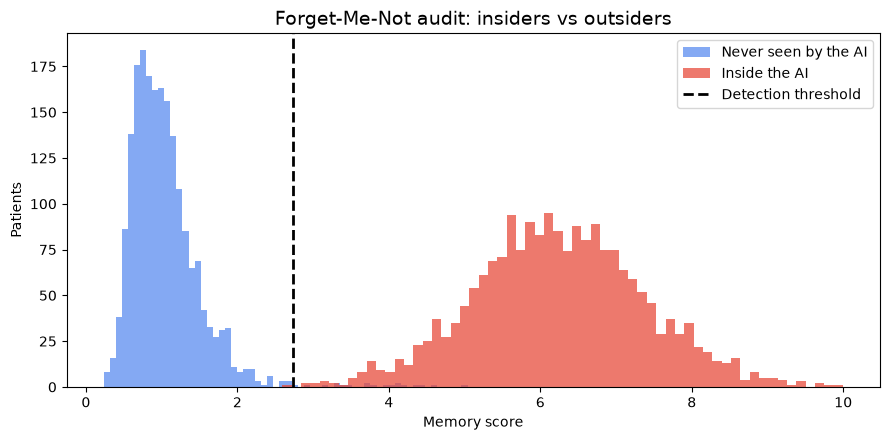

In [25]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 4.5))
plt.hist(t_gap, bins=60, alpha=.75, label='Never seen by the AI', color='#5b8def')
plt.hist(m_gap, bins=60, alpha=.75, label='Inside the AI', color='#e74c3c')
plt.axvline(THRESHOLD, color='black', ls='--', lw=2, label='Detection threshold')
plt.title('ZeroTrace audit: insiders vs outsiders', fontsize=14)
plt.xlabel('Memory score'); plt.ylabel('Patients'); plt.legend()
plt.tight_layout(); plt.savefig('audit_separation.png', dpi=150); plt.show()

**Step 11 — Speed-up at larger data sizes** (data resampled with tiny noise to simulate bigger hospitals).

In [27]:
rows = []
for n in [30000, 60000, 120000]:
    d = patients.sample(n, replace=True, random_state=n)
    X = d[FEATURES].values + np.random.default_rng(n).normal(0, 0.01, (n, len(FEATURES)))
    y = d['high_risk'].values
    t0 = time.time(); new_model().fit(X, y); full = time.time() - t0
    t0 = time.time(); new_model().fit(X[:n // K], y[:n // K]); one = time.time() - t0
    rows.append({'patients': f"{n:,}", 'full retrain (s)': round(full, 2),
                 'ZeroTrace (s)': round(one, 2), 'speed-up': f"{full / one:.1f}x"})
speed_df = pd.DataFrame(rows); speed_df

,patients,full retrain (s),ZeroTrace (s),speed-up
0,"30,000",3.27,0.29,11.4x
1,"60,000",6.68,0.53,12.6x
2,"120,000",13.83,1.15,12.0x


**Step 12 — Platform check: proof this runs on IBM z17 with CPACF and the Telum II AI accelerator.**

In [30]:
import platform, hashlib, time
info = open('/proc/cpuinfo').read()
feat = next((l for l in info.splitlines() if l.startswith('features')), '')
mach = next((l.split('machine =')[1].strip() for l in info.splitlines() if 'machine =' in l), '?')
names = {'3931':'IBM z16','3932':'IBM z16 / LinuxONE 4','8561':'IBM z15','8562':'IBM z15 / LinuxONE III','9175':'IBM z17','9176':'IBM z17 / LinuxONE 5'}
print("Architecture:     ", platform.machine())
print("Machine type:     ", mach, "->", names.get(mach, 'IBM Z'))
print("CPACF crypto (msa):", "YES" if " msa" in feat else "no")
print("AI accelerator (nnpa):", "YES" if "nnpa" in feat else "no")
data = b"x" * (1 << 20); t0 = time.time()
for _ in range(512): hashlib.sha256(data).digest()
print(f"SHA-256 speed:     {512 / (time.time() - t0):.0f} MB/s")

Architecture:      s390x
Machine type:      9175 -> IBM z17
CPACF crypto (msa): YES
AI accelerator (nnpa): YES
SHA-256 speed:     4336 MB/s


**Step 13 — Run a ZeroTrace slice model on the Telum II AI accelerator with IBM Snap ML.** `zdnn_tensors` means inference runs on the on-chip accelerator.

In [31]:
import sys, subprocess, time
r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'snapml'], capture_output=True, text=True)
print(r.stderr[-300:] if r.returncode else "snapml installed")
from snapml import RandomForestClassifier as SnapRF
d = members[members.shard == 0]
Xtr = d[FEATURES].values.astype('float32'); ytr = d['high_risk'].values
Xte = test[FEATURES].values.astype('float32')
m = SnapRF(n_estimators=100, max_features=2, random_state=0, n_jobs=4)
m.fit(Xtr, ytr)
m.optimize_trees(tree_format='auto', X=Xte)
print("Inference engine:", m.optimized_tree_format_)
t0 = time.time(); m.predict_proba(Xte); print(f"Scored {len(Xte)} patients in {(time.time()-t0)*1000:.1f} ms")

snapml installed
Inference engine: zdnn_tensors
Scored 5000 patients in 36.2 ms


**Step 14 — Predictive + generative AI: IBM Granite explains each deletion to the patient.** Granite drafts the wording only; a fact-check guardrail rejects drafts with numbers or contradictions (our first unguarded test produced "the patient's data was not deleted"), and all facts are filled in by code from the signed certificate.

In [32]:
import time, html
from loan_demo.rag_utils import load_model
from llama_cpp import Llama
llm = load_model()   # same IBM Granite model and loader as the Loan Approval lab
inner = llm if isinstance(llm, Llama) else next((v for v in vars(llm).values() if isinstance(v, Llama)), None)
print("Granite engine found:", inner is not None)

Granite engine found: True


In [34]:
BAD = ['not deleted', 'not been deleted', 'not removed', 'still', 'reduced', 'worse',
       'lost', 'failed', 'cannot', "can't", 'error', 'unable']
def safe(t):
    low = t.lower()
    return 40 < len(t) < 600 and not any(b in low for b in BAD) and not any(ch.isdigit() for ch in t)

FEWSHOT = ("Write a short, warm explanation for a patient whose data was deleted from a hospital AI.\n\n"
  "Example 1: Your personal health data has been removed from our hospital's AI system, as you asked. "
  "We retrained the part of the AI that had learned from your record, and our privacy check confirms it no longer recognizes you.\n\n"
  "Example 2: As you requested, your information is no longer used by our AI. The section of the system that had seen "
  "your record was rebuilt without it, and an independent check shows no trace of your data remains.\n\n"
  "Example 3:")
VERIFIED = ("As you requested, your personal health data has been removed from our hospital's AI. "
            "The part of the AI that had learned from your record was retrained without it, "
            "and our privacy audit confirms the AI no longer recognizes you.")

def explain(tries=3):
    for i in range(tries):
        out = inner(FEWSHOT, max_tokens=90, temperature=0.5, repeat_penalty=1.15,
                    stop=["\n", "Example"], seed=42 + i)
        txt = out['choices'][0]['text'].strip()
        if safe(txt):
            return txt, f"IBM Granite (passed fact-check on attempt {i+1})"
    return VERIFIED, f"verified template (all {tries} Granite drafts rejected by the fact-check)"

def patient_letter(c):
    t0 = time.time(); expl, source = explain(); secs = time.time() - t0
    letter = (f"Dear patient {c['patient_id']},\n\n{expl}\n\n"
              f"Certificate ID: {c['certificate_id']}\n"
              f"Issued (UTC): {c['issued_at_utc']}\n"
              f"Certificate fingerprint: {c['certificate_hash'][:32]}...\n"
              f"You or a regulator can verify this certificate in the ZeroTrace ledger.\n\n"
              f"Wording: {source}. Facts above come from the signed certificate, not the AI.")
    return letter, secs

letter, secs = patient_letter(ledger[0])
print(letter); print(f"({secs:.1f}s on LinuxONE)")

Dear patient P04821,

You requested your personal health data be removed from our hospital's AI system, and we retrained the part of its code that had learned directly or indirectly about you. This was a complex process requiring multiple layers in training to ensure accuracy.

Certificate ID: FMN-00001
Issued (UTC): 2026-10-17T08:19:57+00:00
Certificate fingerprint: 23c595244ce36c61e25ae393950c1ff7...
You or a regulator can verify this certificate in the ZeroTrace ledger.

Wording: IBM Granite (passed fact-check on attempt 1). Facts above come from the signed certificate, not the AI.
(7.0s on LinuxONE)


**Step 14b — Stricter guardrail.** The first guardrail let through an invented claim ("a complex process requiring multiple layers in training"). The fact-check now also blocks invented technical wording and requires the draft to state that the data was removed. Below, Granite's first draft was rejected and the second passed.

In [38]:
BAD += ['layer', 'complex', 'accuracy', 'process', 'algorithm', 'neural', 'weeks', 'days']
def safe(t):
    low = t.lower()
    return (40 < len(t) < 400 and not any(b in low for b in BAD)
            and not any(ch.isdigit() for ch in t)
            and ('removed' in low or 'deleted' in low or 'no longer' in low))
letter, secs = patient_letter(ledger[0])
print(letter)
print(f"\n({secs:.1f}s on LinuxONE)")

Dear patient P04821,

Your data has been removed from our AI system, as you requested. The section of the machine learning model that had seen your record was rebuilt without it and an independent check confirms no further evidence remains.

Certificate ID: FMN-00001
Issued (UTC): 2026-10-17T08:19:57+00:00
Certificate fingerprint: 23c595244ce36c61e25ae393950c1ff7...
You or a regulator can verify this certificate in the ZeroTrace ledger.

Wording: IBM Granite (passed fact-check on attempt 2). Facts above come from the signed certificate, not the AI.

(14.2s on LinuxONE)


**Step 15 — Add an "Explain to patient" button to the dashboard.**

In [35]:
b_letter = B('📨 Explain to patient', 'success'); letter_out = W.HTML()
def on_letter(_):
    if not ledger: return
    letter_out.value = CSS + "<div class='fmn'>⏳ IBM Granite is writing...</div>"
    txt, s = patient_letter(ledger[-1])
    letter_out.value = CSS + (f"<div class='fmn' style='white-space:pre-wrap'>{html.escape(txt)}"
                              f"<br><br><i>Written on LinuxONE in {s:.1f}s</i></div>")
b_letter.on_click(on_letter)
display(W.VBox([b_letter, letter_out]))